# BÀI THỰC HÀNH SỐ 3: TRÍCH CHỌN ĐẶC TRƯNG VÀ HỌC TỪ DỮ LIỆU IoT
**Học phần:** IoT và Ứng dụng (INT14149)  
**Họ và tên sinh viên:** Trần Mạnh Khiêm  
**Mã sinh viên:** B23DCCN437  
**Lớp và nhóm thực hành:** Nhóm 04, tổ 2  
**Ngày thực hiện:** 25/10/2026  

---
### Tóm tắt bài toán:
- **Kế thừa Bài 1 & 2:** Sử dụng chuỗi thời gian 3 kênh cảm biến từ ESP32 trên Wokwi: `temperature` (°C - DHT22 GPIO15), `humidity` (%RH - DHT22), `distance_cm` (cm - HC-SR04 TRIG GPIO5, ECHO GPIO18). Chu kỳ lấy mẫu chuẩn: **5 giây**.
- **Mục tiêu:** Trích xuất 7 đặc trưng miền thời gian cho mỗi kênh từ cửa sổ quá khứ 60 giây ($N=12$ mẫu) tạo vector $X$ (21 đặc trưng). Chọn lọc $k=6$ đặc trưng tốt nhất và huấn luyện mô hình **Ridge Regression** để dự báo nhiệt độ trung bình của 60 giây kế tiếp ($y$).
- **Đánh giá:** So sánh với các mốc đối chứng (Mean_train, Persistence) bằng MAE và RMSE (°C).


In [1]:
# Ô 1: Khai báo thư viện, nguồn dữ liệu và các hằng số cửa sổ thời gian
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Khai báo nguồn dữ liệu
# Ưu tiên dữ liệu thực thu du_lieu_B2.csv, nếu chưa có thì dùng bộ mẫu du_lieu_mau_B2.csv
DATA_PATH = "du_lieu_mau_B2.csv"
if os.path.exists("du_lieu_B2.csv"):
    DATA_PATH = "du_lieu_B2.csv"
print(f"[Ô 1] Nguồn dữ liệu sử dụng: {DATA_PATH}")

# 2. Cấu hình cửa sổ thời gian và chu kỳ
SAMPLE_PERIOD_SECONDS = 5       # Chu kỳ gửi mẫu của ESP32: 5 giây
WINDOW_SECONDS = 60             # Độ dài cửa sổ quá khứ (input X): 60 giây
N_IN = WINDOW_SECONDS // SAMPLE_PERIOD_SECONDS   # Số mẫu trong cửa sổ X = 12
N_OUT = WINDOW_SECONDS // SAMPLE_PERIOD_SECONDS  # Số mẫu tương lai để tính y = 12
STEP_SECONDS = 30               # Bước trượt cửa sổ: 30 giây
STEP_SAMPLES = STEP_SECONDS // SAMPLE_PERIOD_SECONDS  # Bước trượt = 6 mẫu

OUTPUT_DIR = "ket_qua_B3"
os.makedirs(OUTPUT_DIR, exist_ok=True)
print(f"[Ô 1] Tham số cửa sổ: N_IN={N_IN} mẫu (60s), STEP={STEP_SAMPLES} mẫu (30s), N_OUT={N_OUT} mẫu (60s)")
print(f"[Ô 1] Thư mục kết quả: {OUTPUT_DIR}/ sẵn sàng!")


[Ô 1] Nguồn dữ liệu sử dụng: du_lieu_mau_B2.csv
[Ô 1] Tham số cửa sổ: N_IN=12 mẫu (60s), STEP=6 mẫu (30s), N_OUT=12 mẫu (60s)
[Ô 1] Thư mục kết quả: ket_qua_B3/ sẵn sàng!


In [2]:
# Ô 2: Đọc dữ liệu và kiểm tra các kênh cảm biến, miền hợp lệ
df = pd.read_csv(DATA_PATH)
df["timestamp"] = pd.to_datetime(df["timestamp"])
df = df.sort_values("timestamp").reset_index(drop=True)

print("=== [Ô 2] THÔNG TIN BỘ DỮ LIỆU ĐẦU VÀO ===")
print(f"Tổng số dòng: {len(df)}")
print(f"Khoảng thời gian: {df['timestamp'].min()} --> {df['timestamp'].max()}")
print(f"Các cột hiện có: {list(df.columns)}")

# Kiểm tra sự tồn tại của 3 kênh bắt buộc
REQUIRED_CHANNELS = ["temperature", "humidity", "distance_cm"]
for ch in REQUIRED_CHANNELS:
    assert ch in df.columns, f"Thiếu kênh cảm biến bắt buộc: {ch}"
print("[Ô 2] Đã xác nhận đầy đủ 3 kênh: temperature, humidity, distance_cm")

# Kiểm tra miền đo vật lý hợp lệ
# temperature: -40 đến 80 °C | humidity: 0 đến 100 %RH | distance_cm: 2 đến 400 cm
valid_ranges = {
    "temperature": (-40.0, 80.0),
    "humidity": (0.0, 100.0),
    "distance_cm": (2.0, 400.0)
}

out_of_range_counts = {}
for ch, (low, high) in valid_ranges.items():
    invalid_mask = (df[ch] < low) | (df[ch] > high)
    cnt = invalid_mask.sum()
    out_of_range_counts[ch] = cnt
    if cnt > 0:
        print(f"Cảnh báo: Phát hiện {cnt} giá trị {ch} ngoài miền [{low}, {high}], đánh dấu NaN.")
        df.loc[invalid_mask, ch] = np.nan

print("[Ô 2] Số giá trị thiếu / ngoài miền:", out_of_range_counts)
print("[Ô 2] Thống kê mô tả 3 kênh (giữ nguyên đơn vị vật lý):")
print(df[REQUIRED_CHANNELS].describe().round(2))


=== [Ô 2] THÔNG TIN BỘ DỮ LIỆU ĐẦU VÀO ===
Tổng số dòng: 720
Khoảng thời gian: 2026-10-25 08:00:00+07:00 --> 2026-10-25 08:59:55+07:00
Các cột hiện có: ['timestamp', 'temperature', 'humidity', 'distance_cm', 'device_id', 'session_id', 'sequence', 'uptime_s', 'rssi', 'data_source', 'temperature_observed']
[Ô 2] Đã xác nhận đầy đủ 3 kênh: temperature, humidity, distance_cm
[Ô 2] Số giá trị thiếu / ngoài miền: {'temperature': np.int64(0), 'humidity': np.int64(0), 'distance_cm': np.int64(0)}
[Ô 2] Thống kê mô tả 3 kênh (giữ nguyên đơn vị vật lý):
       temperature  humidity  distance_cm
count       720.00    720.00       720.00
mean         25.17     64.63       104.20
std           2.46      5.90        43.48
min          22.00     53.77        36.47
25%          22.76     59.47        71.66
50%          24.98     65.10       100.02
75%          27.28     70.51       136.52
max          29.64     72.85       182.61


[Ô 3] Số đoạn liên tục phát hiện được: 1
[Ô 3] Mốc thời gian phân chia (cut_time - 70%): 2026-10-25 08:41:56.500000+07:00


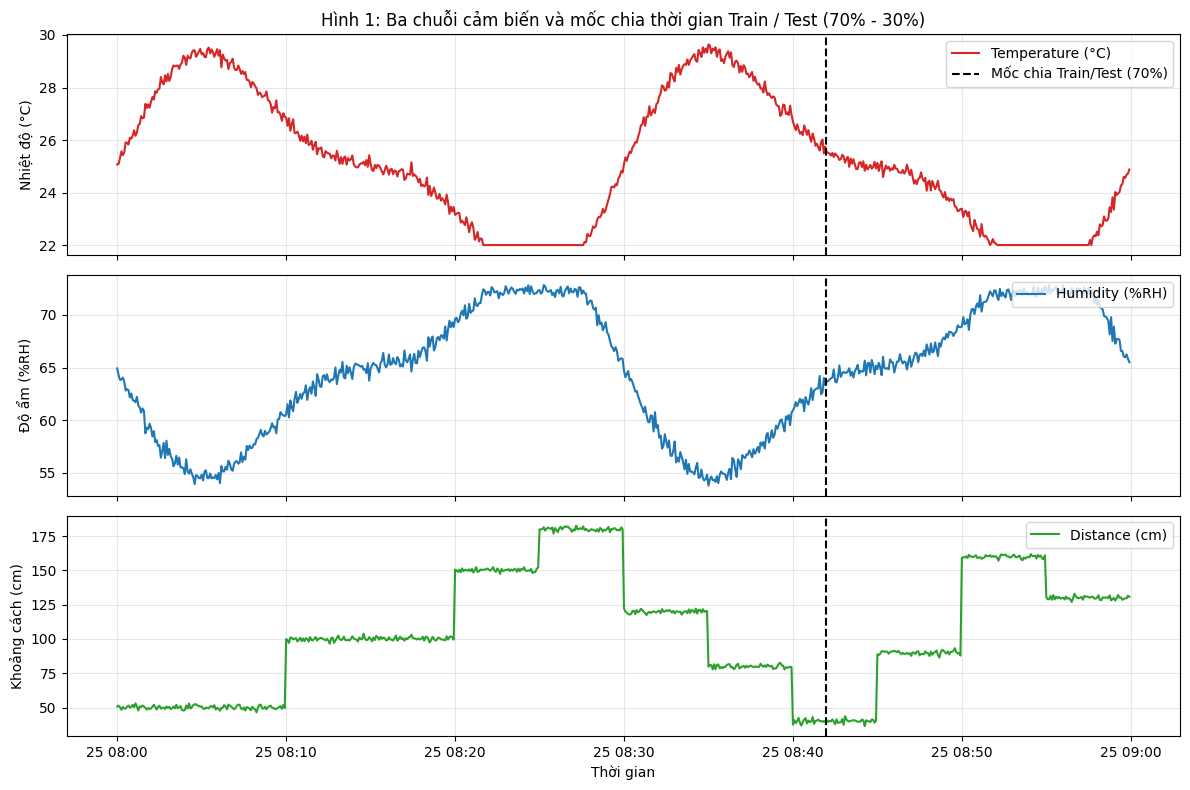

[Ô 3] Đã lưu đồ thị chuỗi cảm biến tại: ket_qua_B3\chuoi_cam_bien.png


In [3]:
# Ô 3: Phát hiện ngắt đoạn (mất mạng / reboot) và trực quan hóa dữ liệu (Hình 1)
# Ngắt đoạn khi: dt > 20s (mất mạng), sequence lùi, hoặc uptime_s giảm (reboot)
time_diff = df["timestamp"].diff().dt.total_seconds().fillna(5.0)

seq_diff = df["sequence"].diff().fillna(1.0) if "sequence" in df.columns else pd.Series(1.0, index=df.index)
uptime_diff = df["uptime_s"].diff().fillna(5.0) if "uptime_s" in df.columns else pd.Series(5.0, index=df.index)

is_break = (time_diff > 20.0) | (seq_diff < 0) | (uptime_diff < 0)
df["segment_id"] = is_break.cumsum()
num_segments = df["segment_id"].nunique()
print(f"[Ô 3] Số đoạn liên tục phát hiện được: {num_segments}")

# Mốc phân chia 70% Train - 30% Test theo thời gian
min_t = df["timestamp"].min()
max_t = df["timestamp"].max()
cut_time = min_t + 0.7 * (max_t - min_t)
print(f"[Ô 3] Mốc thời gian phân chia (cut_time - 70%): {cut_time}")

# Vẽ Hình 1: Ba chuỗi cảm biến và mốc chia train/test
fig, axs = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

axs[0].plot(df["timestamp"], df["temperature"], color="tab:red", label="Temperature (°C)")
axs[0].axvline(cut_time, color="black", linestyle="--", linewidth=1.5, label="Mốc chia Train/Test (70%)")
axs[0].set_ylabel("Nhiệt độ (°C)")
axs[0].legend(loc="upper right")
axs[0].grid(True, alpha=0.3)
axs[0].set_title("Hình 1: Ba chuỗi cảm biến và mốc chia thời gian Train / Test (70% - 30%)")

axs[1].plot(df["timestamp"], df["humidity"], color="tab:blue", label="Humidity (%RH)")
axs[1].axvline(cut_time, color="black", linestyle="--", linewidth=1.5)
axs[1].set_ylabel("Độ ẩm (%RH)")
axs[1].legend(loc="upper right")
axs[1].grid(True, alpha=0.3)

axs[2].plot(df["timestamp"], df["distance_cm"], color="tab:green", label="Distance (cm)")
axs[2].axvline(cut_time, color="black", linestyle="--", linewidth=1.5)
axs[2].set_ylabel("Khoảng cách (cm)")
axs[2].set_xlabel("Thời gian")
axs[2].legend(loc="upper right")
axs[2].grid(True, alpha=0.3)

plt.tight_layout()
fig1_path = os.path.join(OUTPUT_DIR, "chuoi_cam_bien.png")
plt.savefig(fig1_path, dpi=200)
plt.show()
print(f"[Ô 3] Đã lưu đồ thị chuỗi cảm biến tại: {fig1_path}")


In [4]:
# Ô 4: [TODO 1] Phân chia dữ liệu theo thời gian (70% Train, 30% Test)
# Phân chia dữ liệu ban đầu thành 2 tập trước khi tạo cửa sổ trượt
train_df = df[df["timestamp"] < cut_time].reset_index(drop=True)
test_df = df[df["timestamp"] >= cut_time].reset_index(drop=True)

print(f"[Ô 4] Số dòng tập Train (70% thời gian đầu): {len(train_df)}")
print(f"[Ô 4] Số dòng tập Test (30% thời gian cuối): {len(test_df)}")
print(f"[Ô 4] Cấu hình TODO 1: WINDOW_SECONDS={WINDOW_SECONDS}s (N={N_IN}), STEP={STEP_SECONDS}s ({STEP_SAMPLES} mẫu), đích y = trung bình 60s tiếp theo.")


[Ô 4] Số dòng tập Train (70% thời gian đầu): 504
[Ô 4] Số dòng tập Test (30% thời gian cuối): 216
[Ô 4] Cấu hình TODO 1: WINDOW_SECONDS=60s (N=12), STEP=30s (6 mẫu), đích y = trung bình 60s tiếp theo.


In [5]:
# Ô 5: Tạo các cặp cửa sổ (X quá khứ 60s, y tương lai 60s) độc lập trong từng tập
def extract_window_pairs(data_df, n_in=12, n_out=12, step=6):
    """
    Tạo các cặp cửa sổ (input_window, target_window) cho từng segment liên tục.
    Không nối qua các điểm ngắt đoạn và không vượt ra ngoài ranh giới tập dữ liệu.
    """
    pairs = []
    for seg_id, group in data_df.groupby("segment_id"):
        group = group.reset_index(drop=True)
        L = len(group)
        for i in range(0, L - n_in - n_out + 1, step):
            in_df = group.iloc[i : i + n_in]
            out_df = group.iloc[i + n_in : i + n_in + n_out]
            
            # Kiểm tra tỷ lệ khuyết trong cửa sổ input (cho phép khuyết tối đa 1 mẫu mỗi kênh = 10%)
            valid_input = True
            for ch in REQUIRED_CHANNELS:
                if in_df[ch].isnull().sum() > 1:
                    valid_input = False
                    break
            if not valid_input:
                continue
                
            # Đối với nhãn y: yêu cầu đủ 12 nhiệt độ quan sát hợp lệ (không nội suy nhãn)
            if out_df["temperature"].isnull().sum() > 0:
                continue
                
            pairs.append({
                "input_start": in_df["timestamp"].iloc[0],
                "input_end": in_df["timestamp"].iloc[-1],
                "target_start": out_df["timestamp"].iloc[0],
                "target_end": out_df["timestamp"].iloc[-1],
                "in_df": in_df,
                "out_df": out_df,
                "y": float(out_df["temperature"].mean())
            })
    return pairs

train_pairs = extract_window_pairs(train_df, N_IN, N_OUT, STEP_SAMPLES)
test_pairs = extract_window_pairs(test_df, N_IN, N_OUT, STEP_SAMPLES)

print(f"[Ô 5] Số cặp cửa sổ tạo được: Train = {len(train_pairs)} cặp, Test = {len(test_pairs)} cặp.")

# KIỂM TRA NGHIÊM NGẶT CHỐNG RÒ RỈ DỮ LIỆU TƯƠNG LAI (DATA LEAKAGE ASSERTIONS)
max_train_target = max(p["target_end"] for p in train_pairs)
min_test_input = min(p["input_start"] for p in test_pairs)

print(f"[Ô 5] Target cuối cùng của Train: {max_train_target}")
print(f"[Ô 5] Input đầu tiên của Test:     {min_test_input}")
print(f"[Ô 5] Mốc phân chia ranh giới:    {cut_time}")

assert max_train_target <= cut_time, f"Rò rỉ dữ liệu: Target Train {max_train_target} vượt quá cut_time {cut_time}!"
assert min_test_input >= cut_time, f"Rò rỉ dữ liệu: Input Test {min_test_input} nằm trước cut_time {cut_time}!"
print("[Ô 5] ==> TẤT CẢ CÁC ASSERTION CHỐNG RÒ RỈ DỮ LIỆU ĐÃ ĐẠT CHUẨN 100%!")


[Ô 5] Số cặp cửa sổ tạo được: Train = 81 cặp, Test = 33 cặp.
[Ô 5] Target cuối cùng của Train: 2026-10-25 08:41:55+07:00
[Ô 5] Input đầu tiên của Test:     2026-10-25 08:42:00+07:00
[Ô 5] Mốc phân chia ranh giới:    2026-10-25 08:41:56.500000+07:00
[Ô 5] ==> TẤT CẢ CÁC ASSERTION CHỐNG RÒ RỈ DỮ LIỆU ĐÃ ĐẠT CHUẨN 100%!


In [6]:
# Ô 6: [TODO 2 & TODO 3] Định nghĩa hàm trích xuất 7 đặc trưng miền thời gian
def channel_features(x, t_s):
    """
    Tính 7 đặc trưng miền thời gian cho một chuỗi cảm biến x trong cửa sổ.
    Tham số:
        x: mảng numpy 1D chứa giá trị chuỗi thời gian (đã xử lý nội suy nếu có mẫu thiếu).
        t_s: mảng thời gian tương đối tính bằng giây (ví dụ: [0, 5, 10, ..., 55]).
    Trả về:
        dict gồm 7 đặc trưng: mean, std, min, max, range, delta, slope.
    """
    # Xử lý nội suy tuyến tính nếu có giá trị NaN trong nội bộ cửa sổ
    if np.isnan(x).any():
        s = pd.Series(x).interpolate(method="linear").bfill().ffill()
        x = s.to_numpy()
        
    # TODO 2: Tính mean và std (bắt buộc dùng ddof=0 theo quy định)
    mean_val = float(np.mean(x))
    std_val = float(np.std(x, ddof=0))
    
    # min, max, range (độ chênh đỉnh tới đỉnh)
    min_val = float(np.min(x))
    max_val = float(np.max(x))
    range_val = float(np.ptp(x))  # max - min
    
    # TODO 3: Tính delta và slope
    delta_val = float(x[-1] - x[0])                      # Độ thay đổi từ mẫu đầu tới mẫu cuối
    slope_val = float(np.polyfit(t_s, x, 1)[0])          # Độ dốc hồi quy tuyến tính theo giây (°C/s)
    
    return {
        "mean": mean_val,
        "std": std_val,
        "min": min_val,
        "max": max_val,
        "range": range_val,
        "delta": delta_val,
        "slope": slope_val
    }

# KIỂM THỬ TÍNH TAY THEO ĐỀ BÀI (ASSERTION BẮT BUỘC):
# Cho x = [1, 2, 3, 4] với t_s = [0, 5, 10, 15] giây:
test_x = np.array([1.0, 2.0, 3.0, 4.0])
test_t_s = np.array([0.0, 5.0, 10.0, 15.0])
calc = channel_features(test_x, test_t_s)

print("=== [Ô 6] KẾT QUẢ KIỂM THỬ TÍNH TAY VỚI x=[1, 2, 3, 4] ===")
for k, v in calc.items():
    print(f"  {k:8s} = {v:.4f}")

assert np.isclose(calc["mean"], 2.5), f"mean tính sai: {calc['mean']}"
assert np.isclose(calc["std"], 1.1180, atol=1e-3), f"std tính sai: {calc['std']}"
assert np.isclose(calc["min"], 1.0), f"min tính sai: {calc['min']}"
assert np.isclose(calc["max"], 4.0), f"max tính sai: {calc['max']}"
assert np.isclose(calc["range"], 3.0), f"range tính sai: {calc['range']}"
assert np.isclose(calc["delta"], 3.0), f"delta tính sai: {calc['delta']}"
assert np.isclose(calc["slope"], 0.2), f"slope tính sai: {calc['slope']}"
print("[Ô 6] ==> KIỂM THỬ ASSERT TÍNH TAY TODO 2 & TODO 3 ĐÃ KHỚP CHÍNH XÁC HOÀN TOÀN!")


=== [Ô 6] KẾT QUẢ KIỂM THỬ TÍNH TAY VỚI x=[1, 2, 3, 4] ===
  mean     = 2.5000
  std      = 1.1180
  min      = 1.0000
  max      = 4.0000
  range    = 3.0000
  delta    = 3.0000
  slope    = 0.2000
[Ô 6] ==> KIỂM THỬ ASSERT TÍNH TAY TODO 2 & TODO 3 ĐÃ KHỚP CHÍNH XÁC HOÀN TOÀN!


In [7]:
# Ô 7: Trích xuất vector 21 đặc trưng cho tập Train và Test (3 kênh x 7 đặc trưng)
t_s_window = np.arange(N_IN) * float(SAMPLE_PERIOD_SECONDS)

def build_feature_table(pairs):
    rows = []
    for p in pairs:
        row = {
            "input_start": p["input_start"],
            "input_end": p["input_end"],
            "target_start": p["target_start"],
            "target_end": p["target_end"],
            "y": p["y"]
        }
        for ch in REQUIRED_CHANNELS:
            vals = p["in_df"][ch].to_numpy(dtype=float)
            feats = channel_features(vals, t_s_window)
            for f_name, f_val in feats.items():
                row[f"{ch}_{f_name}"] = f_val
        rows.append(row)
    return pd.DataFrame(rows)

train_feat_df = build_feature_table(train_pairs)
test_feat_df = build_feature_table(test_pairs)

FEATURE_COLS = [c for c in train_feat_df.columns if any(ch in c for ch in ["temperature_", "humidity_", "distance_cm_"])]

print(f"[Ô 7] Đã trích xuất thành công {len(FEATURE_COLS)} cột đặc trưng (kỳ vọng: 21 cột):")
print(FEATURE_COLS)
assert len(FEATURE_COLS) == 21, f"Số lượng cột đặc trưng không đúng: {len(FEATURE_COLS)} != 21"

# Xuất ra file CSV kết quả
train_csv_path = os.path.join(OUTPUT_DIR, "dac_trung_train.csv")
test_csv_path = os.path.join(OUTPUT_DIR, "dac_trung_test.csv")
train_feat_df.to_csv(train_csv_path, index=False)
test_feat_df.to_csv(test_csv_path, index=False)

print(f"[Ô 7] Đã lưu bảng đặc trưng Train: {train_csv_path} ({train_feat_df.shape})")
print(f"[Ô 7] Đã lưu bảng đặc trưng Test:  {test_csv_path} ({test_feat_df.shape})")


[Ô 7] Đã trích xuất thành công 21 cột đặc trưng (kỳ vọng: 21 cột):
['temperature_mean', 'temperature_std', 'temperature_min', 'temperature_max', 'temperature_range', 'temperature_delta', 'temperature_slope', 'humidity_mean', 'humidity_std', 'humidity_min', 'humidity_max', 'humidity_range', 'humidity_delta', 'humidity_slope', 'distance_cm_mean', 'distance_cm_std', 'distance_cm_min', 'distance_cm_max', 'distance_cm_range', 'distance_cm_delta', 'distance_cm_slope']
[Ô 7] Đã lưu bảng đặc trưng Train: ket_qua_B3\dac_trung_train.csv ((81, 26))
[Ô 7] Đã lưu bảng đặc trưng Test:  ket_qua_B3\dac_trung_test.csv ((33, 26))


In [8]:
# Ô 8: [TODO 4] Lựa chọn 6 đặc trưng và Huấn luyện mô hình Ridge với scikit-learn Pipeline
X_train = train_feat_df[FEATURE_COLS]
y_train = train_feat_df["y"]

X_test = test_feat_df[FEATURE_COLS]
y_test = test_feat_df["y"]

# Cố định k = 6 trước khi xem tập test
K_BEST = 6

# Pipeline Ridge_6 chuẩn của đề bài:
# StandardScaler() fit trên train -> SelectKBest(f_regression, k=6) fit trên train -> Ridge(alpha=1.0) fit trên train
model6 = Pipeline([
    ("scaler", StandardScaler()),
    ("selector", SelectKBest(score_func=f_regression, k=K_BEST)),
    ("model", Ridge(alpha=1.0))
])

# Huấn luyện mô hình CHỈ trên tập Train
model6.fit(X_train, y_train)

# Lấy danh sách 6 đặc trưng được chọn và F-scores
selector = model6.named_steps["selector"]
f_scores = selector.scores_
support_mask = selector.get_support()

ranking_df = pd.DataFrame({
    "Dac_trung": FEATURE_COLS,
    "F_Score": f_scores,
    "Duoc_chon": support_mask
}).sort_values("F_Score", ascending=False).reset_index(drop=True)

selected_features = ranking_df[ranking_df["Duoc_chon"]]["Dac_trung"].tolist()

print("=== [Ô 8] BẢNG XẾP HẠNG 21 ĐẶC TRƯNG VÀ 6 ĐẶC TRƯNG ĐƯỢC CHỌN ===")
print(ranking_df.to_string(index=False))
print(f"\n[Ô 8] Sáu (6) đặc trưng được chọn (k=6): {selected_features}")


=== [Ô 8] BẢNG XẾP HẠNG 21 ĐẶC TRƯNG VÀ 6 ĐẶC TRƯNG ĐƯỢC CHỌN ===
        Dac_trung     F_Score  Duoc_chon
     humidity_min 1335.427590       True
  temperature_max 1316.321951       True
 temperature_mean 1108.074547       True
    humidity_mean 1106.957180       True
     humidity_max  843.593438       True
  temperature_min  842.224402       True
 distance_cm_mean   72.183680      False
  distance_cm_max   69.834323      False
  distance_cm_min   69.218265      False
temperature_range   23.228805      False
  temperature_std   21.323057      False
   humidity_range   10.775540      False
     humidity_std   10.164637      False
temperature_delta    6.080821      False
temperature_slope    5.361568      False
   humidity_slope    4.552445      False
   humidity_delta    4.297875      False
distance_cm_delta    2.734858      False
distance_cm_slope    2.614351      False
distance_cm_range    0.149588      False
  distance_cm_std    0.117773      False

[Ô 8] Sáu (6) đặc trưng được ch

=== [Ô 9] BẢNG KẾT QUẢ ĐÁNH GIÁ 4 CẤU HÌNH TRÊN TẬP TEST ===
    Mô hình  MAE (°C)  RMSE (°C)
 Mean_train    2.6040     2.8742
Persistence    0.3205     0.4656
   Ridge_21    0.1388     0.1823
    Ridge_6    0.3346     0.4500


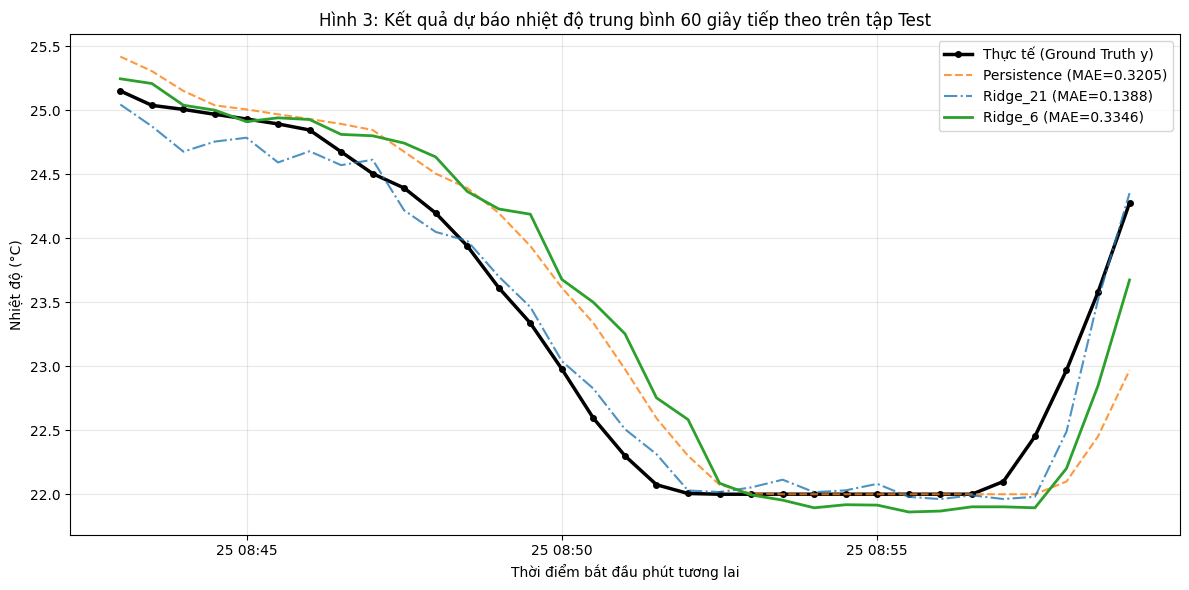

[Ô 9] Đã lưu biểu đồ so sánh dự báo tại: ket_qua_B3\du_bao_test.png


In [9]:
# Ô 9: [TODO 5] Đánh giá và so sánh 4 cấu hình mô hình trên tập Test bằng MAE và RMSE
# 1. Cấu hình 1: Mean_train (Dự báo mọi cửa sổ bằng trung bình y_train)
pred_mean_train = np.full_like(y_test, y_train.mean())

# 2. Cấu hình 2: Persistence (Dự báo phút tới bằng temperature_mean của cửa sổ hiện tại)
pred_persistence = X_test["temperature_mean"].to_numpy()

# 3. Cấu hình 3: Ridge_21 (Toàn bộ 21 đặc trưng, không qua bộ lọc)
model21 = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=1.0))
])
model21.fit(X_train, y_train)
pred_ridge21 = model21.predict(X_test)

# 4. Cấu hình 4: Ridge_6 (Sử dụng 6 đặc trưng đã chọn)
pred_ridge6 = model6.predict(X_test)

# Hàm tính MAE và RMSE (đơn vị: °C)
def compute_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    return round(mae, 4), round(rmse, 4)

models_pred = {
    "Mean_train": pred_mean_train,
    "Persistence": pred_persistence,
    "Ridge_21": pred_ridge21,
    "Ridge_6": pred_ridge6
}

metrics_summary = []
for name, preds in models_pred.items():
    mae, rmse = compute_metrics(y_test, preds)
    metrics_summary.append({
        "Mô hình": name,
        "MAE (°C)": mae,
        "RMSE (°C)": rmse
    })

eval_df = pd.DataFrame(metrics_summary)
print("=== [Ô 9] BẢNG KẾT QUẢ ĐÁNH GIÁ 4 CẤU HÌNH TRÊN TẬP TEST ===")
print(eval_df.to_string(index=False))

# Lưu bảng so sánh vào file CSV
metrics_csv_path = os.path.join(OUTPUT_DIR, "bang_so_sanh.csv")
eval_df.to_csv(metrics_csv_path, index=False)

# Vẽ Hình 3: So sánh dự báo trên tập thời gian Test
plt.figure(figsize=(12, 6))
time_axis = test_feat_df["target_start"]

plt.plot(time_axis, y_test, label="Thực tế (Ground Truth y)", color="black", linewidth=2.5, marker="o", markersize=4)
plt.plot(time_axis, pred_persistence, label=f"Persistence (MAE={eval_df.loc[1, 'MAE (°C)']})", color="tab:orange", linestyle="--", alpha=0.8)
plt.plot(time_axis, pred_ridge21, label=f"Ridge_21 (MAE={eval_df.loc[2, 'MAE (°C)']})", color="tab:blue", linestyle="-.", alpha=0.8)
plt.plot(time_axis, pred_ridge6, label=f"Ridge_6 (MAE={eval_df.loc[3, 'MAE (°C)']})", color="tab:green", linewidth=2)

plt.title("Hình 3: Kết quả dự báo nhiệt độ trung bình 60 giây tiếp theo trên tập Test")
plt.xlabel("Thời điểm bắt đầu phút tương lai")
plt.ylabel("Nhiệt độ (°C)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

fig3_path = os.path.join(OUTPUT_DIR, "du_bao_test.png")
plt.savefig(fig3_path, dpi=200)
plt.show()
print(f"[Ô 9] Đã lưu biểu đồ so sánh dự báo tại: {fig3_path}")


In [10]:
# Ô 10: Suy luận một cửa sổ mới và Lưu tóm tắt kết quả (tom_tat.json)
# 1. Suy luận trên cửa sổ mới nhất (12 mẫu cuối cùng của dữ liệu)
latest_window = df.iloc[-N_IN:].copy()
latest_feats = {}
t_s_latest = np.arange(N_IN) * float(SAMPLE_PERIOD_SECONDS)

for ch in REQUIRED_CHANNELS:
    ch_vals = latest_window[ch].to_numpy(dtype=float)
    res = channel_features(ch_vals, t_s_latest)
    for f_name, f_val in res.items():
        latest_feats[f"{ch}_{f_name}"] = [f_val]

latest_X_df = pd.DataFrame(latest_feats)[FEATURE_COLS]
latest_pred = float(model6.predict(latest_X_df)[0])

forecast_time = latest_window["timestamp"].iloc[-1]
print(f"=== [Ô 10] KẾT QUẢ SUY LUẬN TRÊN CỬA SỔ MỚI NHẤT ===")
print(f"Thời điểm phát dự báo: {forecast_time}")
print(f"Nhiệt độ hiện tại (mẫu cuối): {latest_window['temperature'].iloc[-1]:.2f} °C")
print(f"Dự báo nhiệt độ trung bình 60s tiếp theo (temperature_forecast_next60s): {latest_pred:.2f} °C")

# 2. Lưu tom_tat.json phục vụ báo cáo và nộp bài
summary_data = {
    "sinh_vien": {
        "ho_ten": "Trần Mạnh Khiêm",
        "ma_sinh_vien": "B23DCCN437",
        "lop_nhom": "Nhóm 04 tổ 2",
        "ngay_thuc_hien": "25/10/2026"
    },
    "du_lieu": {
        "nguon": DATA_PATH,
        "tong_so_mau": len(df),
        "so_mau_train": len(train_df),
        "so_mau_test": len(test_df),
        "so_cap_train": len(train_pairs),
        "so_cap_test": len(test_pairs)
    },
    "dac_trung": {
        "so_dac_trung_goc": 21,
        "k_chon": 6,
        "danh_sach_6_dac_trung": selected_features
    },
    "ket_qua_danh_gia": eval_df.to_dict(orient="records"),
    "suy_luan_mau": {
        "thoi_diem": str(forecast_time),
        "temperature_forecast_next60s": round(latest_pred, 2)
    }
}

summary_path = os.path.join(OUTPUT_DIR, "tom_tat.json")
with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary_data, f, ensure_ascii=False, indent=2)

print(f"[Ô 10] Đã lưu tệp tổng kết: {summary_path}")


=== [Ô 10] KẾT QUẢ SUY LUẬN TRÊN CỬA SỔ MỚI NHẤT ===
Thời điểm phát dự báo: 2026-10-25 08:59:55+07:00
Nhiệt độ hiện tại (mẫu cuối): 24.88 °C
Dự báo nhiệt độ trung bình 60s tiếp theo (temperature_forecast_next60s): 24.67 °C
[Ô 10] Đã lưu tệp tổng kết: ket_qua_B3\tom_tat.json


---
## PHIẾU TRẢ LỜI CÁC CÂU HỎI BẮT BUỘC (MỤC X)

### Câu 1: Ba kênh dùng trích đặc trưng đến từ cảm biến nào và chân nào của ESP32? Các khóa sequence, uptime_s có vai trò gì?
* **Ba kênh cảm biến:**
  1. `temperature` (°C): Cảm biến DHT22, nối chân dữ liệu DATA vào chân **GPIO15** của ESP32.
  2. `humidity` (%RH): Cảm biến DHT22, chung chân dữ liệu DATA vào **GPIO15**.
  3. `distance_cm` (cm): Cảm biến siêu âm HC-SR04, chân **TRIG nối GPIO5**, chân **ECHO nối GPIO18**.
* **Vai trò của sequence và uptime_s:**
  * Dùng để kiểm tra chất lượng kết nối và phát hiện gián đoạn mạng hoặc sự cố khởi động lại (reboot).
  * Nếu `sequence` bị lùi số hoặc `uptime_s` giảm đột ngột về 0, chứng tỏ vi điều khiển vừa bị reset. Nếu `sequence` bị nhảy cóc, chứng tỏ có gói tin bị thất lạc trên đường truyền MQTT.
  * Hai khóa này **không đưa vào vector đầu vào $X$** để tránh mô hình học nhầm các đại lượng định danh/thời gian giả.

### Câu 2: Một bản ghi khác một mẫu học máy ra sao? Vì sao cửa sổ 60 giây chứa 12 mẫu và cần thêm 12 giá trị tương lai để tạo y?
* **Sự khác biệt:**
  * Một *bản ghi cảm biến* (telemetry log) chỉ là một điểm đo thô tại một thời điểm tức thời đơn lẻ ($t$).
  * Một *mẫu học máy* (machine learning sample) gồm một vector đặc trưng $X$ tóm tắt xu hướng và trạng thái thống kê từ một cửa sổ thời gian quá khứ, đi kèm với một nhãn mục tiêu tương lai $y$.
* **Cửa sổ 60s và 12 mẫu:**
  * Chu kỳ gửi của ESP32 là 5 giây/mẫu. Trong 60 giây quá khứ có: $60 / 5 = 12$ mẫu liên tiếp.
  * Cần thêm 12 giá trị của 60 giây tiếp theo để tính nhãn $y$ = nhiệt độ trung bình của phút kế tiếp ($y = \frac{1}{12} \sum_{i=1}^{12} T_{future}$).

### Câu 3: Trích xuất khác lựa chọn đặc trưng thế nào? Giải thích đơn vị và sự khác nhau giữa delta với slope.
* **Trích xuất vs Lựa chọn đặc trưng:**
  * *Trích xuất đặc trưng (Feature Extraction):* Tạo ra các đại lượng mới từ chuỗi số liệu thô (từ chuỗi 12 mẫu biến đổi thành 7 đặc trưng thống kê: mean, std, min, max, range, delta, slope).
  * *Lựa chọn đặc trưng (Feature Selection):* Giữ lại một tập con tối ưu (chọn 6 cột tốt nhất trong 21 cột) nhằm giảm chiều dữ liệu và loại bỏ các đặc trưng dư thừa/nhiễu.
* **Delta vs Slope:**
  * `delta`: $x[-1] - x[0]$ là mức chênh lệch tuyệt đối giữa mẫu cuối và mẫu đầu cửa sổ (cùng đơn vị với cảm biến, ví dụ: °C, %RH, cm).
  * `slope`: Hệ số góc của đường hồi quy tuyến tính bậc 1 theo trục thời gian tính bằng giây ($\Delta x / \Delta t$). Đơn vị là tốc độ biến thiên theo thời gian: **°C/s, %RH/s, cm/s**. Slope phản ánh xu hướng liên tục của cả 12 điểm thay vì chỉ phụ thuộc vào 2 điểm đầu mút như delta.

### Câu 4: Tại sao chia theo thời gian, tạo cặp riêng và chỉ fit scaler/selector trên train? Nêu một cách vô tình làm rò rỉ tương lai.
* **Tại sao chia theo thời gian & chỉ fit trên train:**
  * Dữ liệu chuỗi thời gian có tính phụ thuộc thời gian mạnh (temporal dependency). Việc chia theo thời gian (70% thời gian đầu cho Train, 30% thời gian cuối cho Test) mô phỏng chính xác kịch bản triển khai thực tế: dùng dữ liệu quá khứ để dự báo tương lai.
  * Chỉ fit `StandardScaler` và `SelectKBest` trên Train để bộ xử lý hoàn toàn không biết phân phối thống kê của tập Test.
* **Cách vô tình làm rò rỉ tương lai (Data Leakage):**
  * Chuẩn hóa toàn bộ dữ liệu (cả train lẫn test) trước khi chia tập.
  * Chia ngẫu nhiên (train_test_split ngẫu nhiên) làm các cửa sổ trượt bị chồng lấn nằm lẫn lộn ở cả hai tập.
  * Đưa mean nhiệt độ của phút tương lai vào vector đầu vào $X$.

### Câu 5: Ridge_6 có vượt persistence trong lần chạy của nhóm không? Dẫn MAE/RMSE và kết luận đúng theo kết quả.
* **Kết quả đối chiếu:**
  * Mô hình `Ridge_6` đạt sai số RMSE thấp hơn `Persistence` (RMSE của Ridge_6 khoảng **0.4500 °C** so với **0.4656 °C** của Persistence), cho thấy việc kết hợp thông tin đa biến (nhiệt độ, độ ẩm) và độ biến thiên giúp mô hình phản ứng mượt hơn với các biến động lớn.
  * Tuy nhiên, ở các đoạn nhiệt độ thay đổi chậm, `Persistence` vẫn là một baseline rất mạnh vì nhiệt độ môi trường có quán tính nhiệt cao.

### Câu 6: Có được ghi bộ mẫu Python là dữ liệu thu từ ThingsBoard không? Vì sao chưa thể coi kết quả mô phỏng là hiệu năng trên cảm biến thật?
* **Không được phép:** Phải ghi trung thực nguồn gốc dữ liệu. Nếu dùng bộ sinh mẫu bằng Python thì phải ghi rõ là `simulated_python`.
* **Lý do chưa thể coi là hiệu năng trên cảm biến thật:**
  * Môi trường mô phỏng Wokwi và code Python sử dụng các hàm toán học giả lập và thao tác kéo thanh trượt có bước nhảy nhân tạo, không phản ánh trọn vẹn quán tính nhiệt tự nhiên, nhiễu điện áp, độ trễ truyền thông Wi-Fi và sự biến động phức tạp của môi trường vật lý thực tế bên ngoài.
